<a href="https://colab.research.google.com/github/sarkarrajesh20037-debug/e-commerce/blob/main/E_Commerce_Customer_Analytics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# E-Commerce Customer Analytics - SEC D
Predict customer spending, purchase likelihood, product recommendations and customer segments.

**Before running:** run the next cell once to create the dataset.

In [ ]:
%run generate_data.py

1500 customers | 48 products | 8356 transactions


## Imports and setup

In [ ]:
import os
os.makedirs('charts', exist_ok=True); os.makedirs('results', exist_ok=True); os.makedirs('data', exist_ok=True)
import json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, KFold, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import KMeans
from sklearn.metrics import (r2_score, mean_absolute_error, mean_squared_error, accuracy_score,
                             precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, silhouette_score)
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
SEED = 42
PAST_END = pd.Timestamp("2025-12-31")
metrics = {}

def save(name):
    plt.tight_layout(); plt.savefig(f"charts/{name}.png", dpi=130); plt.show()

## Step 1: Collect Data
Load the three tables: **customers** (demographics + browsing activity), **products**, and **transactions** (purchases + ratings).

In [ ]:
customers = pd.read_csv("data/customers.csv")
products = pd.read_csv("data/products.csv")
tx = pd.read_csv("data/transactions.csv", parse_dates=["order_date"])
print("STEP 1 | Raw shapes:", customers.shape, products.shape, tx.shape)

STEP 1 | Raw shapes: (1500, 9) (48, 4) (8356, 6)


## Step 2: Preprocess Data
Remove duplicate rows, fill missing values (median), encode categorical columns (gender, city tier) and merge tables.

In [ ]:
dups = tx.duplicated().sum()
tx = tx.drop_duplicates()
print(f"STEP 2 | Duplicates removed: {dups}")
print("        Missing before:", customers.isna().sum()[lambda s: s > 0].to_dict(),
      tx.isna().sum()[lambda s: s > 0].to_dict())
customers["age"] = customers["age"].fillna(customers["age"].median())
customers["annual_income"] = customers["annual_income"].fillna(customers["annual_income"].median())
tx["rating"] = tx["rating"].fillna(tx["rating"].median())
tx = tx.merge(products, on="product_id", how="left")
tx["amount"] = tx["price"] * tx["quantity"]
# encode categorical data
customers["gender_enc"] = (customers["gender"] == "Female").astype(int)
customers["city_tier_enc"] = customers["city_tier"].str.extract(r"(\d)").astype(int)

STEP 2 | Duplicates removed: 164
        Missing before: {'age': 45, 'annual_income': 45} {'rating': 328}


## Step 3: Analyze Data
Visualise sales trends, popular products, category revenue, spend distribution, spend by city tier, ratings and correlations.

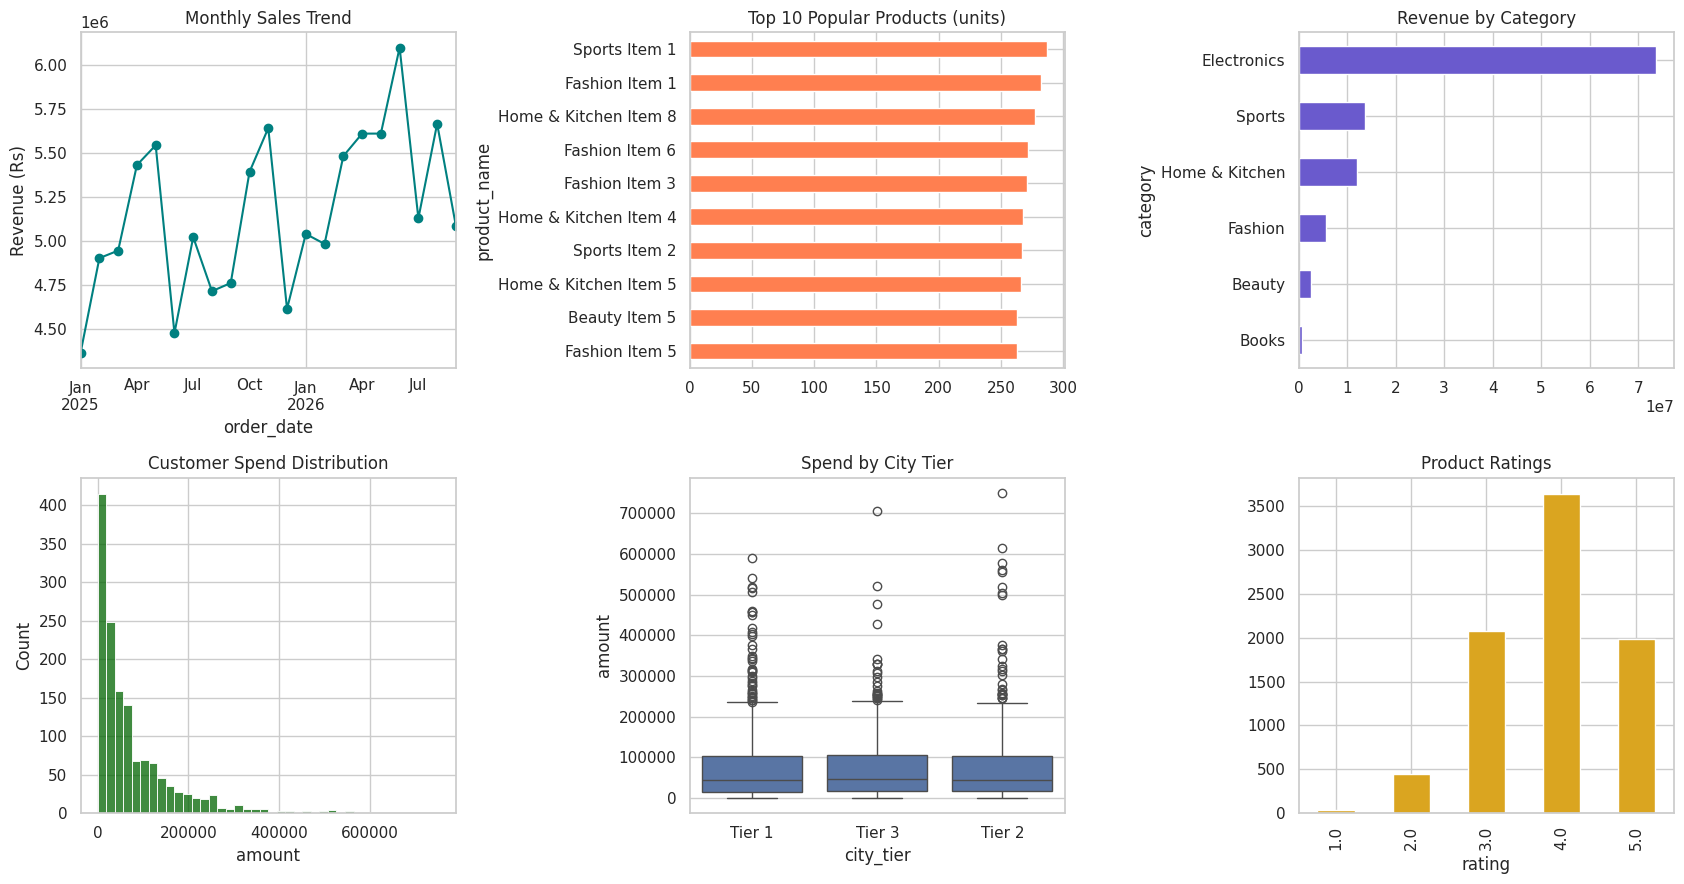

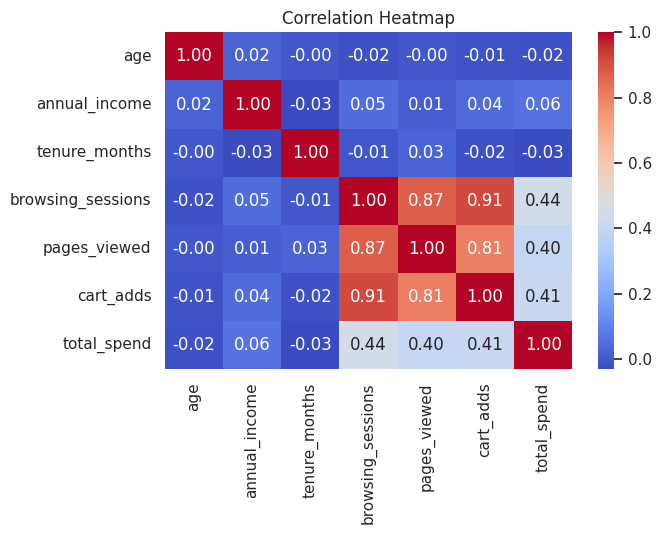

STEP 3 | Charts saved. Total revenue: Rs 108,553,726 | Avg order: Rs 13,251


In [ ]:
full = tx.merge(customers[["customer_id", "age", "gender", "city_tier"]], on="customer_id")
fig, ax = plt.subplots(2, 3, figsize=(17, 9))
tx.groupby(tx.order_date.dt.to_period("M"))["amount"].sum().plot(ax=ax[0, 0], marker="o", color="teal")
ax[0, 0].set_title("Monthly Sales Trend"); ax[0, 0].set_ylabel("Revenue (Rs)")
tx.groupby("product_name")["quantity"].sum().nlargest(10).sort_values().plot.barh(ax=ax[0, 1], color="coral")
ax[0, 1].set_title("Top 10 Popular Products (units)")
tx.groupby("category")["amount"].sum().sort_values().plot.barh(ax=ax[0, 2], color="slateblue")
ax[0, 2].set_title("Revenue by Category")
spend = tx.groupby("customer_id")["amount"].sum()
sns.histplot(spend, bins=40, ax=ax[1, 0], color="darkgreen"); ax[1, 0].set_title("Customer Spend Distribution")
sns.boxplot(data=full.groupby(["customer_id", "city_tier"], as_index=False)["amount"].sum(),
            x="city_tier", y="amount", ax=ax[1, 1]); ax[1, 1].set_title("Spend by City Tier")
tx.groupby("rating").size().plot.bar(ax=ax[1, 2], color="goldenrod"); ax[1, 2].set_title("Product Ratings")
save("01_eda_overview")

corr_df = customers.set_index("customer_id")[["age", "annual_income", "tenure_months", "browsing_sessions",
                                              "pages_viewed", "cart_adds"]].join(spend.rename("total_spend")).fillna(0)
plt.figure(figsize=(7, 5.5)); sns.heatmap(corr_df.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap"); save("02_correlation")
print("STEP 3 | Charts saved. Total revenue: Rs {:,.0f} | Avg order: Rs {:,.0f}".format(tx.amount.sum(), tx.amount.mean()))

## Feature Engineering
Features are built from **2025 (past)** data; targets come from **Jan-Sep 2026 (future)**. This avoids data leakage.

In [ ]:
past, fut = tx[tx.order_date <= PAST_END], tx[tx.order_date > PAST_END]
f = customers.set_index("customer_id").copy()
g = past.groupby("customer_id")
f["past_orders"] = g.size(); f["past_spend"] = g["amount"].sum()
f["avg_order_value"] = g["amount"].mean(); f["avg_rating"] = g["rating"].mean()
f["recency_days"] = (PAST_END - g["order_date"].max()).dt.days
f[["past_orders", "past_spend", "avg_order_value", "avg_rating"]] = f[["past_orders", "past_spend", "avg_order_value", "avg_rating"]].fillna(0)
f["recency_days"] = f["recency_days"].fillna(365)
f["future_spend"] = fut.groupby("customer_id")["amount"].sum().reindex(f.index).fillna(0)
f["future_purchase"] = (fut.groupby("customer_id").size().reindex(f.index).fillna(0) > 0).astype(int)
FEATS = ["age", "gender_enc", "city_tier_enc", "annual_income", "tenure_months", "browsing_sessions",
         "pages_viewed", "cart_adds", "past_orders", "past_spend", "avg_order_value", "avg_rating", "recency_days"]
X = f[FEATS]

## Step 4a: Linear Regression
Predict a customer's **future spending**. Metrics: R2, MAE, RMSE.

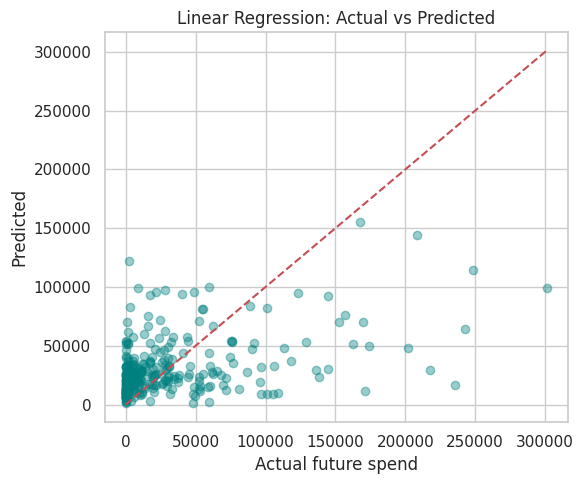

In [ ]:
y = f["future_spend"]
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=.2, random_state=SEED)
lin = make_pipeline(StandardScaler(), LinearRegression()).fit(Xtr, ytr)
p = lin.predict(Xte)
metrics["linear_regression_base"] = dict(R2=r2_score(yte, p), MAE=mean_absolute_error(yte, p),
                                         RMSE=mean_squared_error(yte, p) ** .5)
plt.figure(figsize=(6, 5)); plt.scatter(yte, p, alpha=.4, color="teal")
plt.plot([0, yte.max()], [0, yte.max()], "r--"); plt.xlabel("Actual future spend"); plt.ylabel("Predicted")
plt.title("Linear Regression: Actual vs Predicted"); save("03_linear_regression")

## Step 4b: Logistic Regression
Predict whether a customer will **purchase again** (probability). Metrics: accuracy, precision, recall, F1, ROC-AUC.

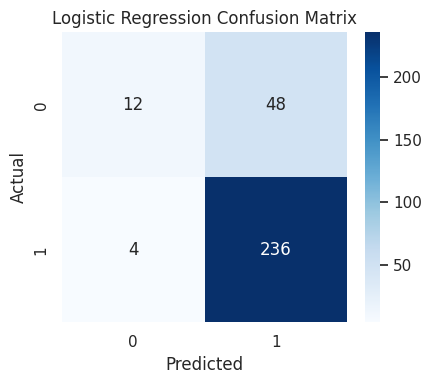

In [ ]:
yc = f["future_purchase"]
Xtr2, Xte2, ytr2, yte2 = train_test_split(X, yc, test_size=.2, random_state=SEED, stratify=yc)
log = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(Xtr2, ytr2)
pp, pc = log.predict_proba(Xte2)[:, 1], log.predict(Xte2)
metrics["logistic_regression_base"] = dict(Accuracy=accuracy_score(yte2, pc), Precision=precision_score(yte2, pc),
                                           Recall=recall_score(yte2, pc), F1=f1_score(yte2, pc), ROC_AUC=roc_auc_score(yte2, pp))
plt.figure(figsize=(4.5, 4)); sns.heatmap(confusion_matrix(yte2, pc), annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Logistic Regression Confusion Matrix"); save("04_logistic_confusion")

## Step 4c: KNN Recommender
Find customers with similar buying patterns (cosine distance) and recommend products they bought. Evaluated with **hit-rate@5**.

In [ ]:
prod_ids = products.product_id.tolist()
def matrix(df):
    return df.pivot_table(index="customer_id", columns="product_id", values="quantity", aggfunc="sum",
                          fill_value=0).reindex(index=f.index, columns=prod_ids, fill_value=0)
M_past, M_fut = matrix(past), matrix(fut)
def recommend(k, M=M_past, n=5):
    nn = NearestNeighbors(n_neighbors=k + 1, metric="cosine", algorithm="brute").fit(M.values)
    dist, idx = nn.kneighbors(M.values)
    recs = {}
    for i, cid in enumerate(M.index):
        sims = 1 - dist[i, 1:]; nbrs = idx[i, 1:]
        score = (M.values[nbrs] > 0).T @ sims
        score[M.values[i] > 0] = -1            # don't re-recommend owned items
        recs[cid] = [prod_ids[j] for j in np.argsort(score)[::-1][:n]]
    return recs
def hit_rate(recs):
    ok = [cid for cid in f.index if M_fut.loc[cid].sum() > 0]
    return np.mean([M_fut.loc[cid, recs[cid]].gt(0).any() for cid in ok])
base_hit = hit_rate(recommend(10)); metrics["knn_base"] = dict(k=10, hit_rate_at_5=base_hit)

## Step 4d: K-Means Segmentation
Cluster customers on Recency, Frequency and Monetary value into **Premium / Regular / Occasional**. Elbow and silhouette plots guide the choice of k.

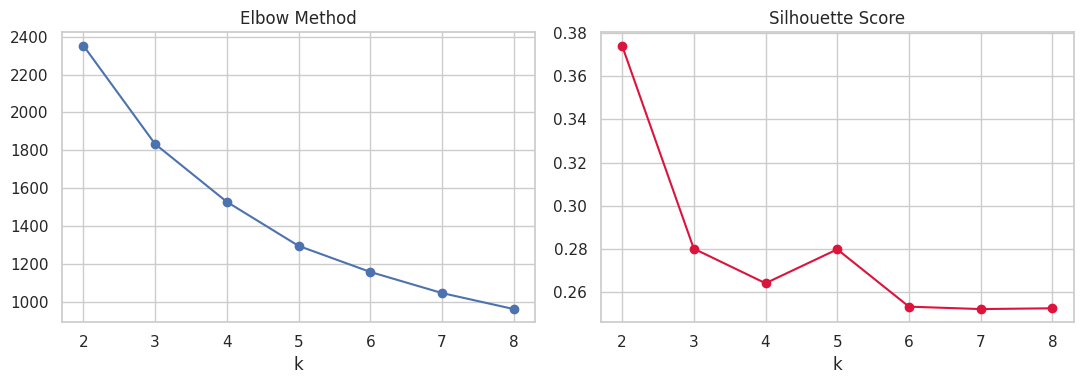

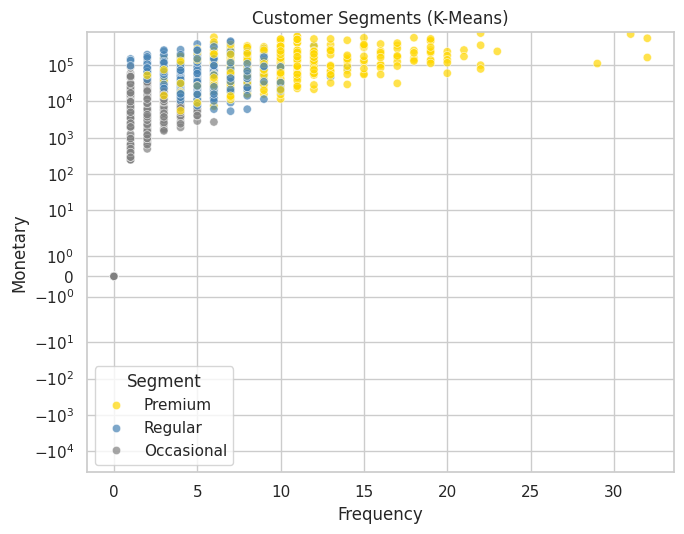

STEP 4 | Segment profile:
             Recency  Frequency  Monetary  Customers
Segment                                            
Premium        26.8        9.5  131153.5        477
Regular       147.1        5.1   74365.3        563
Occasional    319.4        1.7    8969.3        460


In [ ]:
all_g = tx.groupby("customer_id")
rfm = pd.DataFrame({"Recency": (tx.order_date.max() - all_g["order_date"].max()).dt.days,
                    "Frequency": all_g.size(), "Monetary": all_g["amount"].sum()}).reindex(f.index)
rfm["Recency"] = rfm["Recency"].fillna(rfm["Recency"].max() + 30); rfm[["Frequency", "Monetary"]] = rfm[["Frequency", "Monetary"]].fillna(0)
buyers = rfm["Frequency"] > 0                      # customers with no orders are Occasional by definition
Z = StandardScaler().fit_transform(np.log1p(rfm.loc[buyers, ["Recency", "Frequency", "Monetary"]]))
ks = range(2, 9)
inertia = [KMeans(k, n_init=10, random_state=SEED).fit(Z).inertia_ for k in ks]
sil = [silhouette_score(Z, KMeans(k, n_init=10, random_state=SEED).fit_predict(Z)) for k in ks]
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ks, inertia, "o-"); ax[0].set_title("Elbow Method"); ax[0].set_xlabel("k")
ax[1].plot(ks, sil, "o-", color="crimson"); ax[1].set_title("Silhouette Score"); ax[1].set_xlabel("k"); save("05_kmeans_k_selection")
km = KMeans(3, n_init=10, random_state=SEED).fit(Z)
rfm["cluster"] = -1; rfm.loc[buyers, "cluster"] = km.labels_
order = rfm[buyers].groupby("cluster")["Monetary"].mean().sort_values(ascending=False).index
names = dict(zip(order, ["Premium", "Regular", "Occasional"])); names[-1] = "Occasional"
rfm["Segment"] = rfm["cluster"].map(names)
metrics["kmeans"] = dict(k=3, silhouette=silhouette_score(Z, km.labels_), note="clustered on customers with >=1 order; zero-order customers labelled Occasional")
plt.figure(figsize=(7, 5.5)); sns.scatterplot(data=rfm, x="Frequency", y="Monetary", hue="Segment",
                                              hue_order=["Premium", "Regular", "Occasional"], palette=["gold", "steelblue", "gray"], alpha=.7)
plt.yscale("symlog"); plt.title("Customer Segments (K-Means)"); save("06_segments")
seg_profile = rfm.groupby("Segment")[["Recency", "Frequency", "Monetary"]].mean().round(1).loc[["Premium", "Regular", "Occasional"]]
seg_profile["Customers"] = rfm["Segment"].value_counts()
print("STEP 4 | Segment profile:\n", seg_profile)

## Step 5: Optimize and Cross-Validate
Ridge + GridSearchCV for spending, tuned Logistic Regression, best k for KNN, all with 5-fold cross-validation.

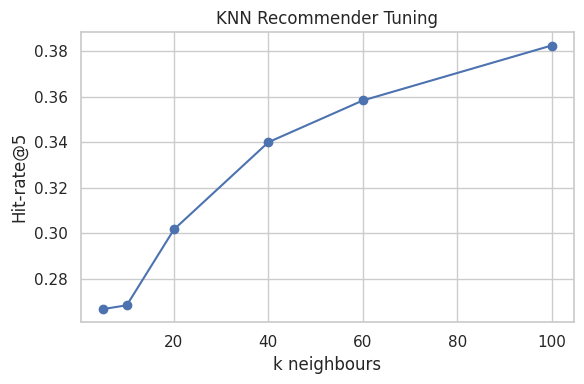

In [ ]:
kf = KFold(5, shuffle=True, random_state=SEED)
base_cv = cross_val_score(make_pipeline(StandardScaler(), LinearRegression()), X, y, cv=kf, scoring="r2")
gs = GridSearchCV(make_pipeline(StandardScaler(), Ridge()), {"ridge__alpha": [0.1, 1, 10, 50, 100, 300, 1000]}, cv=kf, scoring="r2").fit(Xtr, ytr)
p2 = gs.predict(Xte)
metrics["linear_regression_cv_r2_base"] = dict(mean=base_cv.mean(), std=base_cv.std())
metrics["ridge_tuned"] = dict(best_alpha=gs.best_params_["ridge__alpha"], cv_r2=gs.best_score_,
                              R2=r2_score(yte, p2), MAE=mean_absolute_error(yte, p2), RMSE=mean_squared_error(yte, p2) ** .5)

skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
base_auc = cross_val_score(make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)), X, yc, cv=skf, scoring="roc_auc")
gl = GridSearchCV(make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
                  {"logisticregression__C": [0.01, 0.1, 1, 10, 100], "logisticregression__class_weight": [None, "balanced"]},
                  cv=skf, scoring="roc_auc").fit(Xtr2, ytr2)
pp2, pc2 = gl.predict_proba(Xte2)[:, 1], gl.predict(Xte2)
metrics["logistic_cv_auc_base"] = dict(mean=base_auc.mean(), std=base_auc.std())
metrics["logistic_tuned"] = dict(best_params=gl.best_params_, cv_auc=gl.best_score_, Accuracy=accuracy_score(yte2, pc2),
                                 Precision=precision_score(yte2, pc2), Recall=recall_score(yte2, pc2),
                                 F1=f1_score(yte2, pc2), ROC_AUC=roc_auc_score(yte2, pp2))

k_grid = [5, 10, 20, 40, 60, 100]
hits = {k: hit_rate(recommend(k)) for k in k_grid}
best_k = max(hits, key=hits.get)
metrics["knn_tuned"] = dict(best_k=best_k, hit_rate_at_5=hits[best_k], all=hits)
plt.figure(figsize=(6, 4)); plt.plot(list(hits), list(hits.values()), "o-"); plt.xlabel("k neighbours")
plt.ylabel("Hit-rate@5"); plt.title("KNN Recommender Tuning"); save("07_knn_tuning")

## Step 6: Display Results
Final output per customer: predicted spend, purchase probability, segment and recommended products. Saved to `results/final_output.csv`.

In [ ]:
final_X = f[FEATS]
best_lin, best_log = gs.best_estimator_.fit(X, y), gl.best_estimator_.fit(X, yc)
recs = recommend(best_k)
name = products.set_index("product_id")["product_name"]
out = pd.DataFrame({
    "customer_id": f.index,
    "predicted_spend": np.clip(best_lin.predict(final_X), 0, None).round(2),
    "purchase_probability": best_log.predict_proba(final_X)[:, 1].round(3),
    "segment": rfm["Segment"].values,
    "recommended_products": [", ".join(name[r] for r in recs[c][:5]) for c in f.index]})
out.to_csv("results/final_output.csv", index=False)
seg_profile.to_csv("results/segment_profile.csv")
json.dump(metrics, open("results/metrics.json", "w"), indent=2, default=float)

print("\nSTEP 5 | Results (before -> after optimisation)")
print(f" Linear Reg  R2 {metrics['linear_regression_base']['R2']:.3f} -> Ridge R2 {metrics['ridge_tuned']['R2']:.3f}  (5-fold CV R2 {metrics['ridge_tuned']['cv_r2']:.3f})")
print(f" Logistic    AUC {metrics['logistic_regression_base']['ROC_AUC']:.3f} -> {metrics['logistic_tuned']['ROC_AUC']:.3f}  (5-fold CV AUC {gl.best_score_:.3f})  params {gl.best_params_}")
print(f" KNN         Hit@5 {base_hit:.3f} (k=10) -> {hits[best_k]:.3f} (k={best_k})")
print(f" KMeans      silhouette {metrics['kmeans']['silhouette']:.3f}")
print("\nSTEP 6 | FINAL OUTPUT (sample)"); print(out.head(8).to_string(index=False))
print("\nSegment counts:", out.segment.value_counts().to_dict())


STEP 5 | Results (before -> after optimisation)
 Linear Reg  R2 0.192 -> Ridge R2 0.194  (5-fold CV R2 0.203)
 Logistic    AUC 0.781 -> 0.782  (5-fold CV AUC 0.758)  params {'logisticregression__C': 100, 'logisticregression__class_weight': None}
 KNN         Hit@5 0.268 (k=10) -> 0.383 (k=100)
 KMeans      silhouette 0.280

STEP 6 | FINAL OUTPUT (sample)
customer_id  predicted_spend  purchase_probability    segment                                                                                recommended_products
      C0001         56503.93                 0.970    Premium Electronics Item 8, Electronics Item 4, Home & Kitchen Item 8, Sports Item 7, Home & Kitchen Item 3
      C0002         19345.64                 0.870    Premium                       Books Item 5, Books Item 1, Books Item 7, Books Item 4, Home & Kitchen Item 7
      C0003         37915.49                 0.917    Premium                       Sports Item 8, Beauty Item 3, Sports Item 4, Books Item 6, Electronics I